# 03 - Loan-default model
PRD targets: ROC-AUC >= 0.80, recall >= 0.70. Four algorithms (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting standing in for XGBoost - not installed here), customer-grouped 80/20 split, grouped 5-fold CV for tuning, test set touched once. Full training: `python -m src.train`; this notebook re-runs the key steps inline and loads the saved grid.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
from src import features as fe, modeling as M
from src.models import ml_compat as ml
from src.config import PROCESSED, SEED
a = fe.application_features(); d = a[a.loan_default.notna()].reset_index(drop=True); y = d.loan_default.astype(int).values
tr, te = M.group_split(d.customer_id.values, y, 0.2, SEED)
assert not set(d.customer_id.iloc[tr]) & set(d.customer_id.iloc[te])
Xdf, par = fe.design_matrix(d.iloc[tr], fe.NUM_APP, fe.CATEGORICAL_APP); cols = list(Xdf.columns)
Xtr, Xte = Xdf.values, fe.design_matrix(d.iloc[te], fe.NUM_APP, fe.CATEGORICAL_APP, medians=par, columns=cols)[0].values; ytr, yte = y[tr], y[te]
print(f'{len(d)} disbursed loans | default rate {y.mean():.3f} | train {len(tr)} test {len(te)} ({int(yte.sum())} defaults) | {len(cols)} features | backend {ml.BACKEND}')

3403 disbursed loans | default rate 0.234 | train 2722 test 681 (157 defaults) | 55 features | backend mini_sklearn (NumPy fallback, scikit-learn API subset)


## Why the split is by customer
Same-customer rows share identical bureau/transaction features. A random row split leaks them across train and test:

In [2]:
folds = M.group_folds(d.customer_id.values[tr], ytr, 5, SEED)
lr = M.Scaled(ml.LogisticRegression(C=0.01, class_weight='balanced', max_iter=200))
p_grouped = M._clone(lr).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
Xall = np.vstack([Xtr, Xte]); yall = np.r_[ytr, yte]
Xa, Xb, ya, yb = ml.train_test_split(Xall, yall, test_size=.2, random_state=SEED, stratify=yall)
p_naive = M._clone(lr).fit(Xa, ya).predict_proba(Xb)[:, 1]
print('AUC with customer-grouped split:', round(ml.roc_auc_score(yte, p_grouped), 3), '| AUC with naive random row split:', round(ml.roc_auc_score(yb, p_naive), 3))

AUC with customer-grouped split: 0.732 | AUC with naive random row split: 0.752


## Model comparison (tuned by grouped CV on the training set)

In [3]:
grid = pd.read_csv(PROCESSED / 'model_selection_grid.csv'); best = grid.loc[grid.groupby('family').cv_auc_mean.idxmax()]
comp = pd.read_csv(PROCESSED / 'model_comparison.csv'); comp.round(3)

,Model,Stage,CV_AUC,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TN,FP,FN,TP,CV_AUC_std
0,Baseline: predict no default,baseline,0.500,0.769,0.000,0.000,0.000,0.500,0.231,524,0,157,0,NaN
1,Logistic Regression,C=0.003,0.737,0.671,0.373,0.624,0.467,0.731,0.448,359,165,59,98,0.013
2,Decision Tree,"depth=3, leaf=30",0.701,0.653,0.368,0.701,0.482,0.718,0.419,335,189,47,110,0.014
3,Random Forest,"depth=8, leaf=10",0.723,0.715,0.404,0.497,0.446,0.720,0.424,409,115,79,78,0.011
4,Gradient Boosting (XGBoost stand-in),"n=100, depth=2",0.728,0.675,0.383,0.669,0.487,0.735,0.454,355,169,52,105,0.011


In [4]:
best.round(3)

,family,params,cv_auc_mean,cv_auc_std
5,Decision Tree,"depth=3, leaf=30",0.701,0.014
15,Gradient Boosting (XGBoost stand-in),"n=100, depth=2",0.728,0.011
0,Logistic Regression,C=0.003,0.737,0.013
11,Random Forest,"depth=8, leaf=10",0.723,0.011


## Champion, calibration and thresholds
Selected by CV ROC-AUC. Balanced class weights inflate raw probabilities, so a Platt calibration is fitted on out-of-fold predictions; thresholds are chosen on those OOF predictions, never on the test set.

In [5]:
s = json.load(open('../reports/default_model_summary.json'))
print('champion:', s['champion'], s['params'], '| CV AUC', round(s['cv_auc'], 3))
print('test @0.5      :', {k: round(v, 3) for k, v in s['test_default_threshold'].items() if k in ('ROC_AUC', 'PR_AUC', 'Accuracy', 'Precision', 'Recall', 'F1')})
print(f"test @F1-thr {s['threshold_f1']:.3f}:", {k: round(v, 3) for k, v in s['test_at_f1_threshold'].items() if k in ('Precision', 'Recall', 'F1')})
print(f"test @recall70-thr {s['threshold_recall70']:.3f}:", {k: round(v, 3) for k, v in s['test_at_recall70_threshold'].items() if k in ('Precision', 'Recall', 'F1')})
print('PRD targets met?', s['targets'])

champion: Logistic Regression C=0.003 | CV AUC 0.737
test @0.5      : {'Accuracy': 0.777, 'Precision': 0.549, 'Recall': 0.178, 'F1': 0.269, 'ROC_AUC': 0.731, 'PR_AUC': 0.448}
test @F1-thr 0.243: {'Precision': 0.367, 'Recall': 0.586, 'F1': 0.451}
test @recall70-thr 0.224: {'Precision': 0.36, 'Recall': 0.656, 'F1': 0.465}
PRD targets met? {'roc_auc_ge_0_80': False, 'recall_ge_0_70': False}


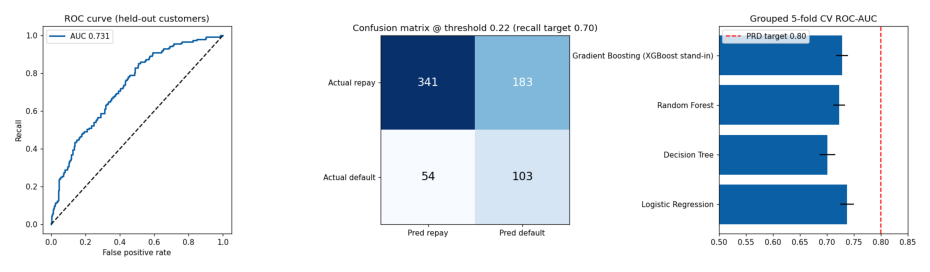

In [6]:
import matplotlib.image as mpimg
fig, ax = plt.subplots(figsize=(17, 4.8)); ax.imshow(mpimg.imread('../images/ml_default_evaluation.png')); ax.axis('off'); plt.show()

## Is the headline number trustworthy? Diagnostics

In [7]:
dg = s['diagnostics']; print('95% CI of test AUC (customer bootstrap):', [round(x, 3) for x in dg['test_auc_95ci_customer_bootstrap']], f"on {dg['test_defaults']} test defaults")
print('naive random split AUC:', round(dg['naive_random_split_auc'], 3))
print('AUC by application year (test):', {k: round(v, 3) for k, v in dg['test_auc_by_application_year'].items()}, 'rows', dg['test_rows_by_application_year'])
print('without bureau features:', round(dg['test_auc_without_bureau_features'], 3), '| without bureau+transactions:', round(dg['test_auc_without_bureau_and_transaction_features'], 3))
print('single-feature AUCs:', {k: round(v, 3) for k, v in dg['single_feature_auc'].items()})

95% CI of test AUC (customer bootstrap): [0.691, 0.773] on 157 test defaults
naive random split AUC: 0.755
AUC by application year (test): {'2022': 0.767, '2023': 0.713, '2024': 0.746} rows {'2022': 160, '2023': 371, '2024': 150}
without bureau features: 0.702 | without bureau+transactions: 0.706
single-feature AUCs: {'debt_to_income_ratio': 0.695, 'credit_score': 0.661, 'loan_to_income': 0.685, 'annual_income': 0.618}


### Interpretation
* **PRD targets not met**: test AUC ~0.73 (95% CI roughly 0.69-0.77) vs the 0.80 target; recall at the business threshold ~0.66 vs 0.70 with precision ~0.36. We did not tune against the test set to chase the target.
* A **single feature (DTI) already gives AUC ~0.70**; the full model adds only ~0.03. Logistic Regression, Gradient Boosting and Random Forest are within ~0.015 CV AUC of each other (the single Decision Tree is lower), so the complex models do not beat regularised logistic regression - the simplest, most explainable model is the champion.
* **Temporal leakage check is reassuring but not conclusive**: removing the bureau features (measured after most applications) drops AUC only from ~0.73 to ~0.70, so the headline does not depend on them; AUC by year shows no clear pattern, but each year has only 150-370 test rows.
* The naive split score (~0.75) is higher than the grouped one (~0.73): customer overlap inflates results, as predicted.

## What drives default?

In [8]:
imp = pd.read_csv(PROCESSED / 'feature_importance.csv'); print(imp.head(10).round(4).to_string(index=False))

                 feature  auc_drop_when_shuffled  abs_coef_standardised
    debt_to_income_ratio                  0.0506                 0.3050
            credit_score                  0.0098                 0.1647
   num_late_payments_30d                  0.0065                 0.0989
        requested_amount                  0.0064                 0.0780
          loan_type_Auto                  0.0038                 0.0393
          loan_to_income                  0.0038                 0.0663
 education_Post Graduate                  0.0035                 0.0446
       num_open_accounts                  0.0029                 0.0467
     loan_type_Education                  0.0025                 0.0352
employment_type_Salaried                  0.0023                 0.0822


PRD expected `credit_score`, DTI, utilisation, prior defaults and employment type to lead. Observed: **DTI dominates**, credit score second, then requested amount and 30-day late payments. Utilisation and prior defaults rank lower once DTI and score are in the model (they overlap with them); employment type matters mainly for the tiny 'Unemployed' group. Cross-check with SQL 7.10: `dti>0.5` has the largest affected population and the highest rate - consistent.